# SEP → astrometria → PSF matching → ZOGY → candidatos → estatística

Este notebook contém os resultados executados nas mesmas oito exposições reais
SPHEREx DR1 de 31/10/2025. O ZOGY foi implementado pelas equações 13–17 e 25–30
[do artigo original](https://arxiv.org/abs/1601.02655). É uma implementação própria
dessas equações, não a instalação do pipeline MeerLICHT/BlackGEM.

**Correção importante:** a máscara antiga rejeitava o flag SOURCE (bit 21), que
marca fontes conhecidas. Isso retirava estrelas úteis. Agora SOURCE é preservado,
e os demais flags de qualidade são rejeitados. O notebook 05 foi reexecutado;
os números armazenados em 03/04 são históricos até que sejam reexecutados.

Referências: [SEP](https://sep.readthedocs.io/en/stable/tutorial.html),
[ePSF oficial SPHEREx](https://caltech-ipac.github.io/irsa-tutorials/spherex-psf/),
[flags, Tabela 16](https://irsa.ipac.caltech.edu/data/SPHEREx/docs/SPHEREx_Expsupp.pdf).

In [17]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table
from IPython.display import JSON, Image, display
from scipy.signal import fftconvolve

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUT = ROOT / "outputs/zogy"
report = json.loads((OUT / "report.json").read_text())
products = np.load(OUT / "products.npz")
print(report["method"])
print(report["data"])
print("Versões:", report["versions"])

Independent ZOGY equations 13–17 and 25–30; SEP source extraction
Eight REAL SPHEREx DR1 detector 1 cutouts, 2025-10-31
Versões: {'numpy': '2.5.4', 'sep': '1.4.1', 'astropy': '8.0.2', 'scipy': '1.18.1'}


## 1. Fontes com SEP

O SEP estima um fundo espacial e extrai fontes com limiar de 4σ usando a
variância dos FITS. Mede também fluxos de abertura. Os catálogos nativos,
inclusive flags de extração, são gravados em `sep_native_0.ecsv` até `7`.
Fonte extraída não significa identificação de asteroide.

In [18]:
rows = []
for e in report["exposures"]:
    rows.append(
        {
            "exposicao": e["exposure"],
            "fontes_SEP": e["sep"]["n_sources"],
            "pixels_SOURCE_preservados": e["source_flag_pixels_preserved"],
            "fracao_valida_registrada": e["valid_fraction"],
        }
    )
display(Table(rows=rows))

exposicao,fontes_SEP,pixels_SOURCE_preservados,fracao_valida_registrada
int64,int64,int64,float64
0,49,5621,0.9561543367346939
1,51,5567,0.9631696428571429
2,50,5325,0.9413265306122449
3,52,5558,0.9656409438775511
4,65,5280,0.9321588010204082
5,43,5315,0.9384566326530612
6,46,5291,0.9272161989795918
7,37,5374,0.9494579081632653


## 2. Alinhamento astrométrico

A primeira WCS calibrada é a referência. Fontes em cada exposição são associadas
por vizinhos mútuos; metade ajusta uma translação e a outra metade verifica o RMS.
Se a correção piora o RMS reservado, a WCS é mantida. A seleção usa esse conjunto
reservado, portanto a medida é um diagnóstico de aceitação, não uma validação
final independente. Não foi feita uma consulta Gaia de calibração absoluta.

Os valores abaixo são de centroides transformados antes do resampling. O registro
usa o pixel nativo mais próximo, rejeitando duplicatas. Essa quantização limita
a precisão das próprias imagens registradas.

In [19]:
rows = []
for e in report["exposures"][1:]:
    a = e["astrometry"]
    rows.append(
        {
            "exposicao": e["exposure"],
            "estrelas_associadas": a["n_matches"],
            "RMS_antes_pixel": a.get("heldout_rms_before_pixels", np.nan),
            "RMS_depois_pixel": a.get("heldout_rms_after_pixels", np.nan),
            "RMS_depois_arcsec": a.get("heldout_rms_after_arcsec", np.nan),
            "resultado": a["status"],
        }
    )
display(Table(rows=rows))

exposicao,estrelas_associadas,RMS_antes_pixel,RMS_depois_pixel,RMS_depois_arcsec,resultado
int64,int64,float64,float64,float64,str24
1,32,0.10021009312433153,0.0966878517310986,0.5946302881462564,translation applied
2,37,0.1536780783849894,0.1536780783849894,0.9451201820676849,WCS retained after check
3,36,0.1371812582411812,0.1371812582411812,0.8436647381832644,WCS retained after check
4,29,0.10712104660886732,0.10712104660886732,0.6587944366445341,WCS retained after check
5,30,0.18481976977908812,0.18167038658086893,1.117272877472344,translation applied
6,19,0.23207213729649837,0.21630545014932281,1.3302785184183354,translation applied
7,13,0.1843937203181241,0.17676788750087727,1.0871225081303952,translation applied


## 3. PSFs e matching

Cada imagem usa a ePSF da zona calibrada mais próxima do centro do recorte,
transformada para a orientação/fase da grade registrada e normalizada. A ePSF
já inclui a resposta do pixel: é amostrada com o oversampling do cabeçalho.
Usar uma única zona/fase em todo o recorte ainda é uma aproximação.

A convolução cruzada N⊗Pr e R⊗Pn fornece uma PSF comum Pn⊗Pr e é testada
separadamente. O ZOGY recebe as imagens originais registradas e suas próprias
PSFs, realizando o matching em Fourier com seu modelo de ruído.

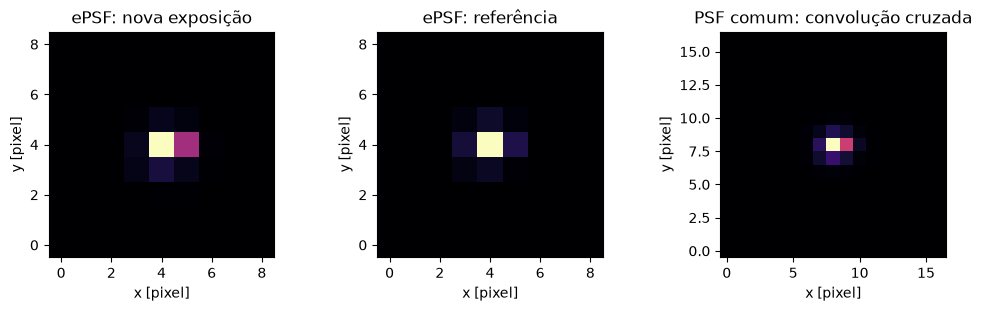

In [20]:
psfs = products["psfs"]
pn, pr = psfs[4], psfs[0]
common = fftconvolve(pn, pr, mode="full")
fig, axes = plt.subplots(1, 3, figsize=(10, 3), layout="constrained")
for ax, data, title in zip(
    axes,
    [pn, pr, common],
    ["ePSF: nova exposição", "ePSF: referência", "PSF comum: convolução cruzada"],
):
    ax.imshow(data, origin="lower", cmap="magma")
    ax.set(title=title, xlabel="x [pixel]", ylabel="y [pixel]")
fig.savefig(OUT / "psf_matching.png", dpi=160)
plt.show()

## 4. Difference Image Analysis com ZOGY

São produzidos D (diferença), S (filtro de detecção) e S_corr (escore corrigido).
A correção propaga os mapas de variância por kernels ao quadrado e inclui um termo
aproximado de erro astrométrico. A variância dos FITS é usada diretamente; não
se adiciona uma contagem de fótons inventada a valores em MJy/sr.

Quatro pares têm cerca de 1,6 h de separação e comprimentos de onda diferentes;
quatro têm comprimentos de onda vizinhos, mas apenas cerca de dois minutos de
separação. O primeiro caso favorece movimento mensurável; o segundo pode cancelar
quase toda a fonte móvel. Nenhum par tem equivalência espectral verificada.

Cinza é máscara. Vermelho/azul são resíduos positivos/negativos; branco é próximo
de zero. A figura usa dados reais **sem injeção**.

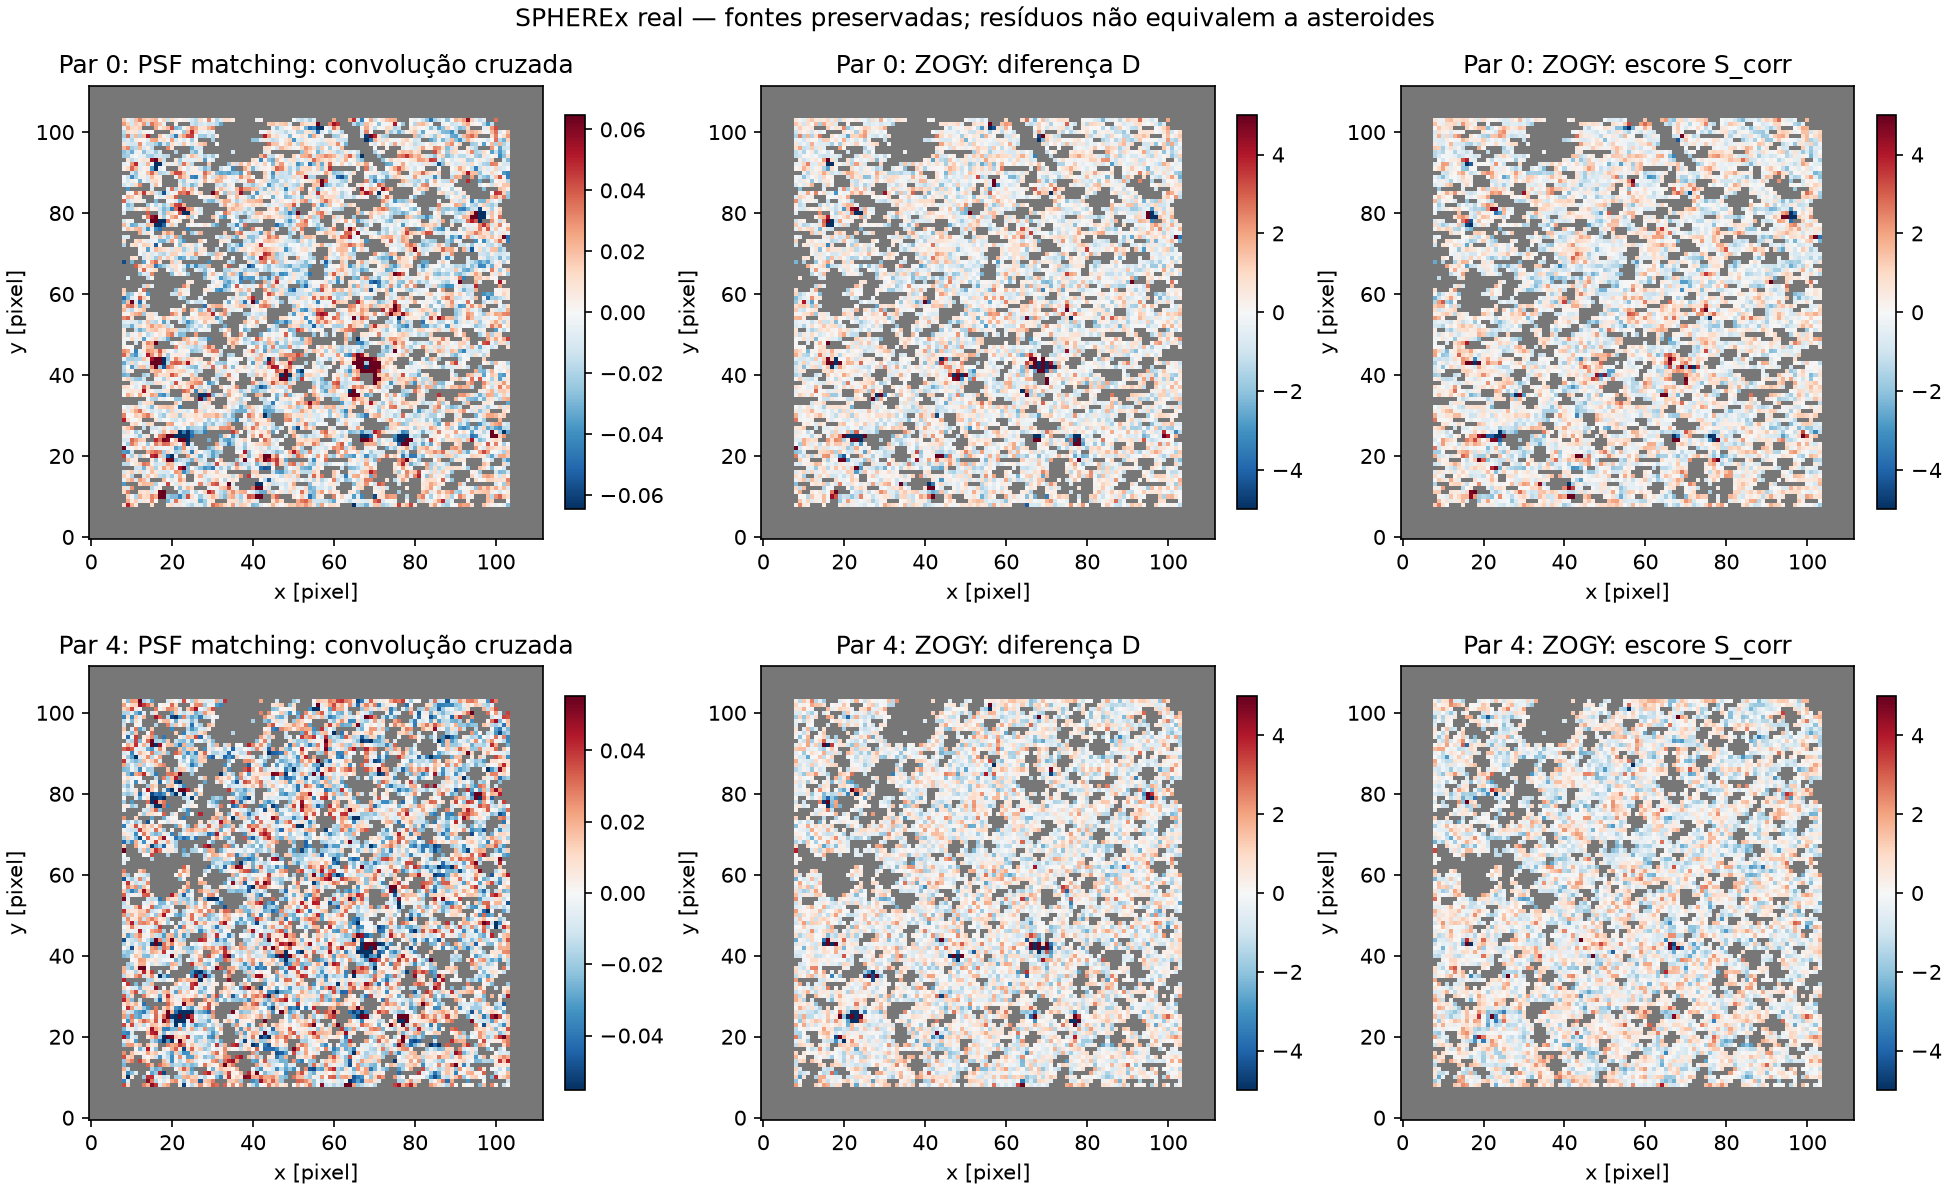

par,nova,referencia,intervalo_h,delta_lambda_um_zona,escala_fotometrica,dispersao_Scorr,picos_positivos,picos_negativos
int64,int64,int64,float64,float64,float64,float64,int64,int64
0,4,0,1.6026819360558875,0.26370882987976074,1.2114000887320369,1.022578172334338,21,11
1,5,1,1.6026814079959877,0.2688175439834595,1.1984081031264031,1.4083493174385655,15,26
2,6,2,1.6026816720259376,0.2743186354637146,1.0589316178078174,2.0302449711884534,16,12
3,7,3,1.602681384072639,0.3016219735145569,1.139794583496998,3.7492398079727702,9,6
4,1,0,0.035814431961625814,0.015404701232910156,1.0145575657372157,1.0293328569304465,9,3
5,3,2,0.03581416793167591,0.01619744300842285,1.0300271505674568,0.9939211755742967,0,0
6,5,4,0.03581390390172601,0.020513415336608887,0.9743504484659598,1.4159476233448585,6,24
7,7,6,0.03581387997837737,0.04350078105926514,1.3908774604640817,3.535056767727085,37,11


In [21]:
display(Image(filename=str(OUT / "comparison.png")))
rows = []
for p in report["pairs"]:
    rows.append(
        {
            "par": p["pair"],
            "nova": p["science"],
            "referencia": p["reference"],
            "intervalo_h": p["gap_hours"],
            "delta_lambda_um_zona": p["zone_wave_difference_um"],
            "escala_fotometrica": p["photometry"]["ratio"],
            "dispersao_Scorr": p["scorr_robust_scale"],
            "picos_positivos": p["positive_candidates"],
            "picos_negativos": p["negative_candidates"],
        }
    )
display(Table(rows=rows))

## 5. Candidatos

O SEP extrai picos positivos e negativos acima de |S_corr|=5. Esses picos podem
ser resíduos de fontes estacionárias, diferenças de cor, PSF ou fundo.
Pares compartilham exposições, portanto a contagem não é de objetos independentes.
As associações de dipolos e trajetórias são exploratórias, sem solução orbital.
Nenhum candidato foi identificado como asteroide conhecido ou descoberta.

In [22]:
print("Picos candidatos, somando todos os pares:", report["n_candidates"])
print(
    "Grupos exploratórios com consistência de dipolo/tempo:",
    len(report["exploratory_dipole_track_groups"]),
)
print("Asteroides confirmados:", report["confirmed_asteroids"])
if report["candidates"]:
    display(
        Table(rows=sorted(report["candidates"], key=lambda c: c["abs_scorr"], reverse=True)[:10])
    )

Picos candidatos, somando todos os pares: 206
Grupos exploratórios com consistência de dipolo/tempo: 2
Asteroides confirmados: 0


pair,science,reference,x,y,sign,abs_scorr,area,sep_flags,bonferroni_p_nominal,conditional_null_max_tail_plus_one,real_sky_statistically_validated
int64,int64,int64,int64,int64,int64,float64,int64,int64,float64,float64,bool
0,4,0,71,42,1,39.99793381217294,1,8,0.0,0.007751937984496124,False
0,4,0,69,42,1,22.872324305940293,1,8,4.5727343346992815e-111,0.007751937984496124,False
7,7,6,17,78,-1,22.443558383991565,10,1,7.718152747609972e-107,0.007751937984496124,False
2,6,2,16,43,-1,20.783355797416764,3,0,3.19458044372109e-91,0.007751937984496124,False
2,6,2,22,25,-1,17.20275523214074,2,8,1.3211228183411065e-61,0.007751937984496124,False
1,5,1,69,42,1,16.879533156580617,1,8,3.3208642843160323e-59,0.007751937984496124,False
3,7,3,15,78,-1,16.222727861652363,168,1,1.8177029582111588e-54,0.007751937984496124,False
3,7,3,97,82,-1,15.927337753811774,273,1,2.136236714957851e-52,0.007751937984496124,False
3,7,3,82,79,-1,14.627430378820861,541,1,9.795970793514937e-44,0.007751937984496124,False


## 6. Validação estatística e injeções

O teste nulo tem 128 realizações de ruído gaussiano com as variâncias, máscaras,
PSFs e escalas ajustadas mantidas fixas. Cada uma gera as oito imagens e reutiliza
as mesmas realizações em seus pares, preservando essa dependência. Compara-se
o máximo absoluto global, além de calcular uma correção de Bonferroni.

É uma validação **condicional de ruído**, sem simular erros de cor, PSF, fundo ou
astrometria. Um p-valor pequeno nesse controle não valida um candidato no céu real.
A dispersão robusta de S_corr deveria ficar próxima de 1 sob o modelo; valores
maiores revelam resíduos ou variâncias não descritas.

As nove injeções usam SNR nominal 3, 5 e 8 em três posições fixas. A fonte aparece
em todas as exposições, inclusive nas referências, com movimento de (3,−2)
pixels/hora. O resultado só conta uma nova recuperação se houver um pico positivo
novo a menos de dois pixels da posição verdadeira. Um pico já presente não conta.
O fluxo varia para manter o SNR nominal; não é um espectro físico de asteroide.
Três posições por intensidade não medem completude da população.

Máximo global 95% no nulo: 4.976337541299572
Fração dos nulos com algum |S_corr| ≥ 5: 0.046875
Intervalo binomial 95%: [0.017394056140272493, 0.0992351236938912]
Limiar Bonferroni nominal para 5%: 4.90001843447929


nominal_single_snr,n_fixed_positions,newly_detected_in_any_long_baseline_pair,population_completeness_measured
float64,int64,int64,bool
3.0,3,0,False
5.0,3,1,False
8.0,3,3,False


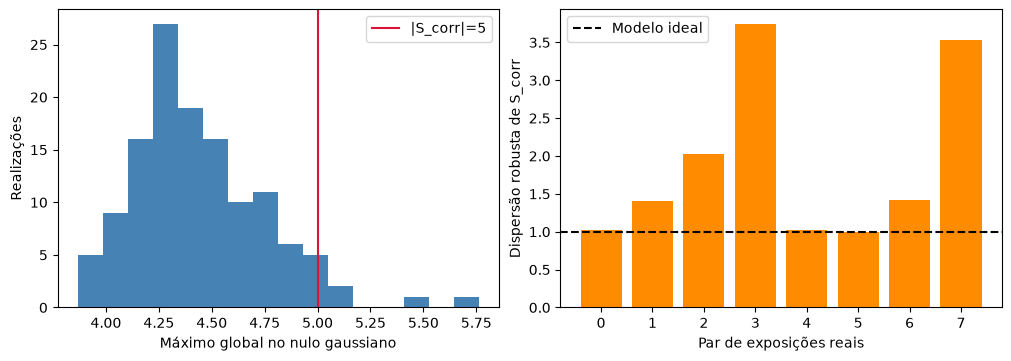

In [23]:
s = report["statistical_validation"]
print("Máximo global 95% no nulo:", s["null_global_max_95percent"])
print("Fração dos nulos com algum |S_corr| ≥ 5:", s["conditional_fwer_at_abs_scorr_5"])
print("Intervalo binomial 95%:", s["conditional_fwer_95percent_binomial_interval"])
print("Limiar Bonferroni nominal para 5%:", s["nominal_two_sided_bonferroni_threshold_05"])
display(Table(rows=report["injection_summary"]))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].hist(s["null_global_maxima"], bins=16, color="steelblue")
axes[0].axvline(5, color="crimson", label="|S_corr|=5")
axes[0].set(xlabel="Máximo global no nulo gaussiano", ylabel="Realizações")
axes[0].legend()
axes[1].bar(
    [p["pair"] for p in report["pairs"]],
    [p["scorr_robust_scale"] for p in report["pairs"]],
    color="darkorange",
)
axes[1].axhline(1, color="black", ls="--", label="Modelo ideal")
axes[1].set(xlabel="Par de exposições reais", ylabel="Dispersão robusta de S_corr")
axes[1].legend()
fig.savefig(OUT / "statistics.png", dpi=160)
plt.show()

## Repetir

```bash
uv run spherex-tracking zogy
uv run --extra dev --extra literature pytest
```

O relatório completo registra máscaras, versões, estrelas usadas, PSFs, pares,
p-valores condicionais e injeções. Os testes automatizados verificam matching
com PSFs diferentes, cancelamento estático, normalização de ruído, posição de
fonte de controle, sinal ao trocar as imagens e ajuste astrométrico conhecido.
As limitações do céu real continuam no relatório; não há declaração de descoberta.

In [24]:
display(JSON(report))

<IPython.core.display.JSON object>